# v3 · 03 The frozen pick on 2023–2024 and on the 2025–26 holdout (design note §5.4–5.5)

The configuration frozen in `outputs/v3/frozen_config.json` is scored here without changes. It is **C3-L**: gradient boosting with v2's settings, balanced class weights, sigmoid-calibrated probabilities, the expected-return rule, and the default-long position. It is refit every January.

| Part | Period | Status (design note §2) |
|---|---|---|
| A · §5.4 | 2023-01 → 2024-12 | **Already seen** (v1 and v2 tests): reported, no claim |
| B · §5.5 | 2025-01-02 → 2026-10-12 | **Primary holdout**, run once. Not blind: v1's follow-up research reported other strategies here, and 2025's broad events are known. |

**Success criterion (fixed in advance):** on the holdout, beat at least 95% of 1,000 random-timing paths with the same time in the market and the same number of switches. Beating Buy & Hold is not required.
**Caveat:** calibration failed §5.1, so none of this is a test of calibration.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config, v2, v3
from src.data import load_snapshot
from src.dataset import build_dataset_v2
from src.evaluate import classification_metrics

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)
OUT = config.OUTPUT_DIR / "v3"; FIG = OUT / "figures"
def savefig(name): plt.savefig(FIG / f"{name}.png", dpi=120, bbox_inches="tight")

FROZEN = json.loads((OUT / "frozen_config.json").read_text())
KIND, DEFAULT, PARAMS = FROZEN["treatment"], FROZEN["default"], FROZEN["params"]
print("frozen:", FROZEN["candidate"], KIND, DEFAULT)

def run_period(ds, prices, rf, years):
    wf = v3.walk_forward_proba(ds, KIND, years, PARAMS)
    er = v3.expected_return(wf)
    pos = v2.positions_from_er(er, DEFAULT)
    held = v2.held_from_positions(pos, start=1 if DEFAULT == "long" else 0)
    days = er.index
    sim = v2.simulate(held, prices.loc[days], rf.loc[days])
    bh_held = v2.buy_and_hold_held(days)
    bh = v2.simulate(bh_held, prices.loc[days], rf.loc[days])
    lab = ds.loc[days, "label"].dropna().astype(int)
    p = wf.loc[lab.index, config.CLASSES]
    cls = classification_metrics(lab, np.array(config.CLASSES)[p.to_numpy().argmax(1)], p.to_numpy())
    return dict(wf=wf, er=er, held=held, sim=sim, bh_held=bh_held, bh=bh, days=days,
                strat=v2.summarize(sim, held, rf.loc[days], f"v3 {FROZEN['candidate']}"),
                bench=v2.summarize(bh, bh_held, rf.loc[days], "Buy & Hold"), cls=cls)

def show(r):
    display(pd.DataFrame([r["strat"], r["bench"]]).set_index("strategy"))
    print("classification (labelled rows):", {k: r["cls"][k] for k in ["n", "accuracy", "macro_f1", "log_loss"]})
    print(f"E[r] range: {r['er'].min():+.4%} … {r['er'].max():+.4%} (exit if below {-v2.ROUND_TRIP:+.2%})")

frozen: C3-L C3 long


## A · 2023–2024 (already seen; reported only)

In [2]:
raw = load_snapshot()
ds = build_dataset_v2(raw)
rf = v2.load_tbill_daily(raw.index)
A = run_period(ds, raw[["Open", "Close"]], rf, [2023, 2024])
show(A)

,final_value,total_return,cagr,ann_vol,sharpe_excess,max_drawdown,round_trips,exposure,total_fees
strategy,,,,,,,,,
v3 C3-L,156546.2500,0.5655,0.2523,0.1283,1.4300,-0.0997,1,1.0000,99.9000
Buy & Hold,156546.2500,0.5655,0.2523,0.1283,1.4300,-0.0997,1,1.0000,99.9000


classification (labelled rows): {'n': 496, 'accuracy': 0.4839, 'macro_f1': 0.3494, 'log_loss': 1.0187}
E[r] range: -0.0910% … +0.5150% (exit if below -0.30%)


## B · Holdout 2025-01-02 → 2026-10-12 (run once)
Data: `data/holdout/spy_20261013.csv` (saved by v1's follow-up research; ends 2026-10-12) and a T-bill snapshot ending at the same date, both saved before scoring. Each yearly fit trains on the holdout file's own history (2006 onward), so prices are adjusted consistently.

In [3]:
HOLD = config.ROOT / "data" / "holdout"
raw_h = pd.read_csv(HOLD / "spy_20261013.csv", index_col=0, parse_dates=True)
assert raw_h.index.max() == pd.Timestamp("2026-10-12"), raw_h.index.max()
irx_path = HOLD / "irx_20261013.csv"
if not irx_path.exists():
    v2.download_tbill_snapshot(end="2026-10-13", path=irx_path)
rf_h = v2.load_tbill_daily(raw_h.index, irx_path)
assert rf_h.loc["2025":].gt(0).all(), "T-bill rate missing for holdout days"
ds_h = build_dataset_v2(raw_h)
B = run_period(ds_h, raw_h[["Open", "Close"]], rf_h, [2025, 2026])
show(B)
print(f"T-bill rate over the holdout, annualised mean: {rf_h.loc['2025':].mean()*252:.2%}")

,final_value,total_return,cagr,ann_vol,sharpe_excess,max_drawdown,round_trips,exposure,total_fees
strategy,,,,,,,,,
v3 C3-L,134409.7400,0.3441,0.1823,0.1694,0.8440,-0.1876,1,1.0000,99.9000
Buy & Hold,134409.7400,0.3441,0.1823,0.1694,0.8440,-0.1876,1,1.0000,99.9000


classification (labelled rows): {'n': 439, 'accuracy': 0.5034, 'macro_f1': 0.3714, 'log_loss': 1.0289}
E[r] range: -0.0277% … +0.5509% (exit if below -0.30%)
T-bill rate over the holdout, annualised mean: 3.89%


## Evidence on the holdout

{
 "round_trips": 1,
 "exposure": 1.0,
 "random_timing_percentile": null,
 "random_timing_note": "not meaningful: the strategy never switched, so every random path with its exposure is the same path",
 "success_criterion_met": null,
 "sharpe_diff_vs_bh_ci95": [
  0.0,
  0.0
 ]
}


""


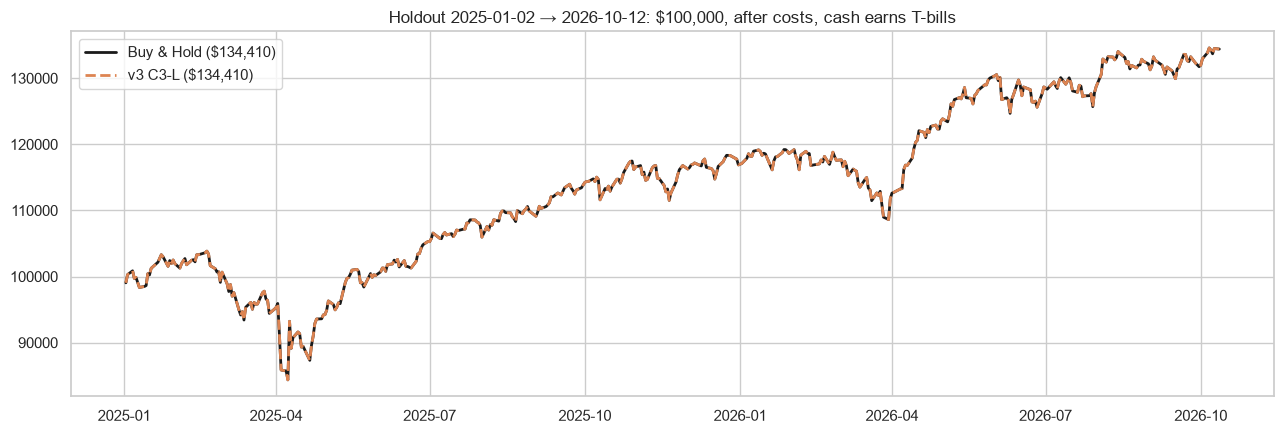

In [4]:
held, sim, bh = B["held"], B["sim"], B["bh"]
ph, rfB = raw_h.loc[B["days"]], rf_h.loc[B["days"]]
trips = B["strat"]["round_trips"]
if trips > 1:
    rand = v2.random_timing_benchmark(held, ph, rfB, n=1000)
    pct = float((rand < sim["value"].iloc[-1]).mean())
else:
    rand, pct = None, None
r_s = sim["value"].pct_change().fillna(sim["value"].iloc[0] / config.INIT_CASH - 1)
r_b = bh["value"].pct_change().fillna(bh["value"].iloc[0] / config.INIT_CASH - 1)
ci = np.percentile(v2.bootstrap_sharpe_diff(r_s, r_b, rfB), [2.5, 97.5])
attr = v2.out_of_market_attribution(held, ph)
EVID = {"round_trips": int(trips), "exposure": B["strat"]["exposure"],
        "random_timing_percentile": None if pct is None else round(pct, 3),
        "random_timing_note": None if pct is not None else "not meaningful: the strategy never switched, so every random path with its exposure is the same path",
        "success_criterion_met": None if pct is None else bool(pct >= 0.95),
        "sharpe_diff_vs_bh_ci95": [round(float(x), 3) for x in ci]}
print(json.dumps(EVID, indent=1))
display(attr)
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(bh["value"], color="k", lw=2, label=f"Buy & Hold (${bh['value'].iloc[-1]:,.0f})")
ax.plot(sim["value"], color="C1", lw=2, ls="--", label=f"v3 {FROZEN['candidate']} (${sim['value'].iloc[-1]:,.0f})")
ax.set_title("Holdout 2025-01-02 → 2026-10-12: $100,000, after costs, cash earns T-bills"); ax.legend()
plt.tight_layout(); savefig("holdout_paths"); plt.show()

## Save

In [5]:
def no_nan(o):
    if isinstance(o, dict): return {k: no_nan(v) for k, v in o.items()}
    if isinstance(o, list): return [no_nan(v) for v in o]
    return None if isinstance(o, float) and np.isnan(o) else o
res = {"frozen": FROZEN["candidate"],
       "secondary_2023_2024": {"strategy": A["strat"], "buy_and_hold": A["bench"], "classification": A["cls"]},
       "holdout_2025_2026": {"strategy": B["strat"], "buy_and_hold": B["bench"], "classification": B["cls"],
                             "evidence": EVID, "attribution": attr.astype(str).to_dict(orient="records")}}
(OUT / "test_and_holdout.json").write_text(json.dumps(no_nan(json.loads(json.dumps(res, default=str))), indent=2, allow_nan=False))
print("saved outputs/v3/test_and_holdout.json, figures/holdout_paths.png")

saved outputs/v3/test_and_holdout.json, figures/holdout_paths.png
